# CUSTOMER ANALYSIS

In [1]:
import pandas as pd

In [3]:
df = pd.read_csv("../data/processed/events_clean.csv", parse_dates=["datetime"])
df.shape

(2755641, 5)

In [4]:
df["datetime"].dtype

dtype('<M8[us]')

## Профиль пользователя

In [7]:
user_profile = df.groupby("visitorid").agg(
    event_count=("event", "size"),
    first_seen=("datetime", "min"),
    last_seen=("datetime", "max"),
)
user_profile

,event_count,first_seen,last_seen
visitorid,,,
0,3,2015-09-11 20:49:49.439,2015-09-11 20:55:17.175
1,1,2015-08-13 17:46:06.444,2015-08-13 17:46:06.444
2,8,2015-08-07 17:51:44.567,2015-08-07 18:20:57.845
3,1,2015-08-01 07:10:35.296,2015-08-01 07:10:35.296
4,1,2015-09-15 21:24:27.167,2015-09-15 21:24:27.167
...,...,...,...
1407575,1,2015-06-10 21:46:08.922,2015-06-10 21:46:08.922
1407576,1,2015-06-03 15:01:29.991,2015-06-03 15:01:29.991
1407577,1,2015-05-17 21:48:04.867,2015-05-17 21:48:04.867


In [9]:
user_profile["active_days"] = (df["datetime"].dt.normalize().groupby(df['visitorid']).nunique())
user_profile.head()

,event_count,first_seen,last_seen,active_days
visitorid,,,,
0,3,2015-09-11 20:49:49.439,2015-09-11 20:55:17.175,1
1,1,2015-08-13 17:46:06.444,2015-08-13 17:46:06.444,1
2,8,2015-08-07 17:51:44.567,2015-08-07 18:20:57.845,1
3,1,2015-08-01 07:10:35.296,2015-08-01 07:10:35.296,1
4,1,2015-09-15 21:24:27.167,2015-09-15 21:24:27.167,1


In [12]:
len(user_profile[user_profile['active_days'] > 1])

143769

In [14]:
round(len(user_profile[user_profile['active_days'] > 1]) / df['visitorid'].nunique() * 100, 2)

10.21

In [15]:
len(user_profile[user_profile['event_count'] == 1])

1001591

In [16]:
round(len(user_profile[user_profile['event_count'] == 1]) / len(user_profile) * 100, 2)

71.16

## Активность и сегменты

In [38]:
user_profile["activity_segment"] = pd.cut(
    user_profile["event_count"],
    bins=[0, 1, 5, 10, 50, float("inf")],
    labels=['1', 'от 2 до 5', 'от 6 до 10', 'от 11 до 50', 'больше 50']
)
user_profile.head()

,event_count,first_seen,last_seen,active_days,activity_segment
visitorid,,,,,
0,3,2015-09-11 20:49:49.439,2015-09-11 20:55:17.175,1,от 2 до 5
1,1,2015-08-13 17:46:06.444,2015-08-13 17:46:06.444,1,1
2,8,2015-08-07 17:51:44.567,2015-08-07 18:20:57.845,1,от 6 до 10
3,1,2015-08-01 07:10:35.296,2015-08-01 07:10:35.296,1,1
4,1,2015-09-15 21:24:27.167,2015-09-15 21:24:27.167,1,1


In [39]:
len(user_profile[user_profile['activity_segment'] == "1" ])

1001591

In [46]:
round(user_profile['activity_segment'].value_counts() / len(user_profile) * 100, 2)

activity_segment
1              71.16
от 2 до 5      24.68
от 6 до 10      2.77
от 11 до 50     1.30
больше 50       0.09
Name: count, dtype: float64

### График

In [47]:
import matplotlib.pyplot as plt

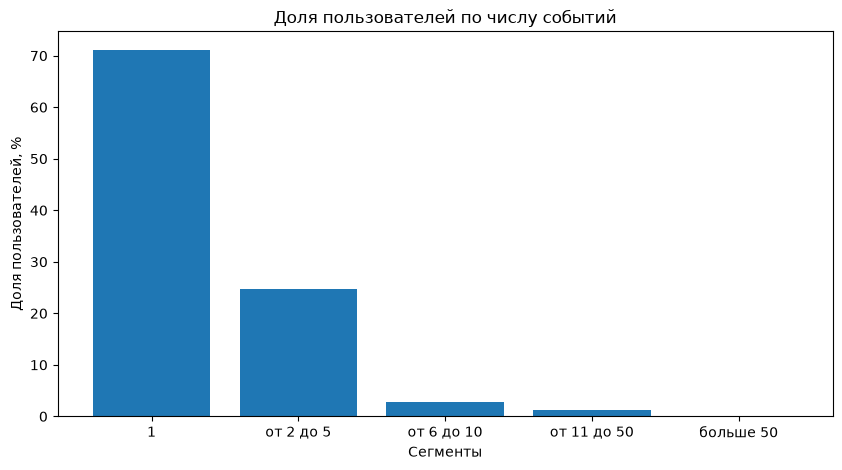

In [49]:
share_bar = round(user_profile['activity_segment'].value_counts() / len(user_profile) * 100, 2)
fig, ax = plt.subplots(figsize = (10,5))
ax.bar(share_bar.index, share_bar.values)
ax.set_title('Доля пользователей по числу событий')
ax.set_xlabel('Сегменты')
ax.set_ylabel('Доля пользователей, %')
plt.show()

### Топ-1%, 5%, 10% пользователей по числу событий

In [82]:
user_profile_sorted = user_profile.sort_values(by = ['event_count', 'visitorid'], ascending = [False,True])

In [83]:
top_1 = int(len(user_profile) * 0.01)
top_5 = int(len(user_profile) * 0.05)
top_10 = int(len(user_profile) * 0.1)

In [84]:
top_1_user = user_profile_sorted.head(top_1)
top_5_user = user_profile_sorted.head(top_5)
top_10_user = user_profile_sorted.head(top_10)

In [85]:
print(round(top_1_user['event_count'].sum() / user_profile['event_count'].sum() * 100, 2))
print(round(top_5_user['event_count'].sum() / user_profile['event_count'].sum() * 100, 2))
print(round(top_10_user['event_count'].sum() / user_profile['event_count'].sum() * 100, 2))

17.52
32.37
42.25


## Типы действий

In [89]:
event_visitor = df.groupby('event')['visitorid'].nunique()

In [91]:
round(event_visitor / df['visitorid'].nunique() * 100, 2)

event
addtocart       2.68
transaction     0.83
view           99.76
Name: visitorid, dtype: float64

Почти все пользователи (99,76%) совершили хотя бы один просмотр. Добавление в корзину встречается у 2,68% пользователей, покупка - у 0,83%. Это доли пользователей с каждым типом события, а не конверсия воронки: один пользователь может входить в несколько групп, а порядок его действий здесь не проверялся.

## Возвраты по неделям

In [102]:
user_profile['cohort_week'] = user_profile['first_seen'].dt.normalize() - pd.to_timedelta(user_profile['first_seen'].dt.weekday, unit = 'D')
user_profile[[ 'first_seen', 'cohort_week']]

,first_seen,cohort_week
visitorid,,
0,2015-09-11 20:49:49.439,2015-09-07
1,2015-08-13 17:46:06.444,2015-08-10
2,2015-08-07 17:51:44.567,2015-08-03
3,2015-08-01 07:10:35.296,2015-07-27
4,2015-09-15 21:24:27.167,2015-09-14
...,...,...
1407575,2015-06-10 21:46:08.922,2015-06-08
1407576,2015-06-03 15:01:29.991,2015-06-01
1407577,2015-05-17 21:48:04.867,2015-05-11


In [105]:
df['activity_week'] = df['datetime'].dt.normalize() - pd.to_timedelta(df['datetime'].dt.weekday, unit = 'D')
df[['datetime', 'activity_week']]

,datetime,activity_week
0,2015-06-02 05:02:12.117,2015-06-01
1,2015-06-02 05:50:14.164,2015-06-01
2,2015-06-02 05:13:19.827,2015-06-01
3,2015-06-02 05:12:35.914,2015-06-01
4,2015-06-02 05:02:17.106,2015-06-01
...,...,...
2755636,2015-08-01 03:13:05.939,2015-07-27
2755637,2015-08-01 03:30:13.142,2015-07-27
2755638,2015-08-01 02:57:00.527,2015-07-27
2755639,2015-08-01 03:08:50.703,2015-07-27


In [106]:
df["cohort_week"] = df["visitorid"].map(user_profile["cohort_week"])
df[["visitorid", "activity_week", "cohort_week"]].head()

,visitorid,activity_week,cohort_week
0,257597,2015-06-01,2015-06-01
1,992329,2015-06-01,2015-05-04
2,111016,2015-06-01,2015-05-25
3,483717,2015-06-01,2015-06-01
4,951259,2015-06-01,2015-06-01


In [107]:
df["cohort_week"].isna().sum()

np.int64(0)

In [112]:
df['week_number'] = (df['activity_week'] - df['cohort_week']).dt.days // 7
df.head()

,visitorid,event,itemid,transactionid,datetime,activity_week,cohort_week,week_number
0,257597,view,355908,NaN,2015-06-02 05:02:12.117,2015-06-01,2015-06-01,0
1,992329,view,248676,NaN,2015-06-02 05:50:14.164,2015-06-01,2015-05-04,4
2,111016,view,318965,NaN,2015-06-02 05:13:19.827,2015-06-01,2015-05-25,1
3,483717,view,253185,NaN,2015-06-02 05:12:35.914,2015-06-01,2015-06-01,0
4,951259,view,367447,NaN,2015-06-02 05:02:17.106,2015-06-01,2015-06-01,0


In [113]:
returned_users = df.groupby(["cohort_week", "week_number"])["visitorid"].nunique()
returned_users.head(10)

cohort_week  week_number
2015-04-27   0              7865
             1               749
             2               322
             3               239
             4               166
             5               146
             6               127
             7               120
             8                96
             9                87
Name: visitorid, dtype: int64

In [114]:
cohort_size = user_profile.groupby("cohort_week").size()


In [115]:

cohort_size.head()

cohort_week
2015-04-27     7865
2015-05-04    71389
2015-05-11    76662
2015-05-18    78427
2015-05-25    73231
dtype: int64

In [116]:
cohort_size.tail()

cohort_week
2015-08-17    65264
2015-08-24    65333
2015-08-31    62329
2015-09-07    71205
2015-09-14    32941
dtype: int64

In [117]:
print("Начало данных:", df["datetime"].min())
print("Конец данных:", df["datetime"].max())

Начало данных: 2015-05-03 03:00:04.384000
Конец данных: 2015-09-18 02:59:47.788000


Данные охватывают период с 3 мая по 18 сентября 2015 года. Неделя с 27 апреля представлена только одним днём, а неделя с 14 сентября обрывается в пятницу. Для сравнения когорт исключаем первую неполную неделю; возвраты учитываем только за полностью завершившиеся недели, последняя из которых начинается 7 сентября.

In [127]:
returned_users = returned_users.reset_index(name = 'returned_users')
returned_users.head()

,cohort_week,week_number,returned_users
0,2015-04-27,0,7865
1,2015-04-27,1,749
2,2015-04-27,2,322
3,2015-04-27,3,239
4,2015-04-27,4,166


In [129]:
returned_users['cohort_size'] = returned_users['cohort_week'].map(cohort_size)
returned_users

,cohort_week,week_number,returned_users,cohort_size
0,2015-04-27,0,7865,7865
1,2015-04-27,1,749,7865
2,2015-04-27,2,322,7865
3,2015-04-27,3,239,7865
4,2015-04-27,4,166,7865
...,...,...,...,...
226,2015-08-31,1,1932,62329
227,2015-08-31,2,545,62329
228,2015-09-07,0,71205,71205
229,2015-09-07,1,1546,71205


In [130]:
first_complete_week = df["activity_week"].min() + pd.Timedelta(weeks=1)
last_complete_week = df["activity_week"].max() - pd.Timedelta(weeks=1)

print(first_complete_week, last_complete_week)

2015-05-04 00:00:00 2015-09-07 00:00:00


In [131]:
returned_users["activity_week"] = (
    returned_users["cohort_week"]
    + pd.to_timedelta(returned_users["week_number"], unit="W")
)

returned_users.head()

,cohort_week,week_number,returned_users,cohort_size,activity_week
0,2015-04-27,0,7865,7865,2015-04-27
1,2015-04-27,1,749,7865,2015-05-04
2,2015-04-27,2,322,7865,2015-05-11
3,2015-04-27,3,239,7865,2015-05-18
4,2015-04-27,4,166,7865,2015-05-25


In [132]:
retention_weeks = returned_users[
    (returned_users["cohort_week"] >= first_complete_week)
    & (returned_users["week_number"].between(1, 4))
    & (returned_users["activity_week"] <= last_complete_week)
].copy()

print(len(retention_weeks))
retention_weeks.head()

66


,cohort_week,week_number,returned_users,cohort_size,activity_week
22,2015-05-04,1,3425,71389,2015-05-11
23,2015-05-04,2,1988,71389,2015-05-18
24,2015-05-04,3,1472,71389,2015-05-25
25,2015-05-04,4,1170,71389,2015-06-01
42,2015-05-11,1,3275,76662,2015-05-18


In [133]:
retention_weeks["retention_pct"] = (
    retention_weeks["returned_users"] / retention_weeks["cohort_size"] * 100
).round(2)

retention_weeks.head()

,cohort_week,week_number,returned_users,cohort_size,activity_week,retention_pct
22,2015-05-04,1,3425,71389,2015-05-11,4.80
23,2015-05-04,2,1988,71389,2015-05-18,2.78
24,2015-05-04,3,1472,71389,2015-05-25,2.06
25,2015-05-04,4,1170,71389,2015-06-01,1.64
42,2015-05-11,1,3275,76662,2015-05-18,4.27


In [134]:
retention_weeks["retention_pct"].min(), retention_weeks["retention_pct"].max()

(np.float64(0.67), np.float64(4.8))

In [135]:
retention_table = retention_weeks.pivot(
    index="cohort_week",
    columns="week_number",
    values="retention_pct"
)

retention_table

week_number,1,2,3,4
cohort_week,,,,
2015-05-04,4.80,2.78,2.06,1.64
2015-05-11,4.27,2.08,1.65,1.21
2015-05-18,3.48,1.91,1.28,1.12
2015-05-25,3.38,1.61,1.22,1.04
2015-06-01,3.36,1.78,1.27,0.99
2015-06-08,3.43,1.66,1.17,1.08
2015-06-15,3.34,1.64,1.35,1.02
2015-06-22,3.37,1.70,1.19,1.02
2015-06-29,3.44,1.67,1.26,0.93


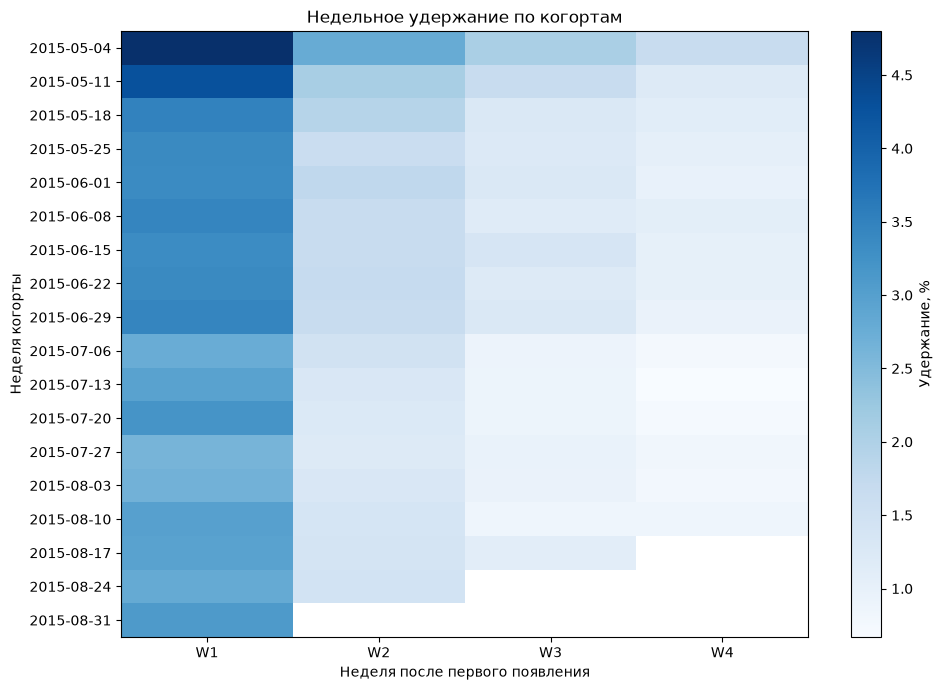

In [139]:
fig, ax = plt.subplots(figsize=(10, 7))
heatmap = ax.imshow(retention_table, aspect="auto", cmap="Blues")

ax.set_xticks(
    range(len(retention_table.columns)),
    labels=[f"W{week}" for week in retention_table.columns]
)
ax.set_yticks(
    range(len(retention_table.index)),
    labels=retention_table.index.strftime("%Y-%m-%d")
)

ax.set_title("Недельное удержание по когортам")
ax.set_xlabel("Неделя после первого появления")
ax.set_ylabel("Неделя когорты")

fig.colorbar(heatmap, ax=ax, label="Удержание, %")
fig.tight_layout()
plt.show()

Недельное удержание невысокое и снижается по мере удаления от первого появления пользователя: у когорты 4 мая оно составляет 4,80% в W1 и 1,64% в W4. У когорт июля-августа удержание в W1 обычно ниже - около 2,6-3,2%. Это наблюдаемое различие, а не доказательство ухудшения продукта: причины по этим данным определить нельзя. Пустые клетки у поздних когорт означают, что соответствующая неделя ещё не завершилась в периоде наблюдения.

## Итоги

Большинство пользователей (71,16%) совершили только одно событие, тогда как на 10% самых активных приходится 42,25% всех событий. Активность аудитории распределена неравномерно.
Недельное удержание низкое: среди когорт с завершённым периодом наблюдения в следующую неделю возвращаются примерно 2,6-4,8% пользователей. В последующие недели доля активных пользователей обычно снижается.
Когорта определяется по первому событию пользователя в доступных данных, а не по дате регистрации. Возвратом считается любое событие в соответствующую неделю. Анализ показывает наблюдаемую динамику, но не устанавливает причины низкого удержания.